# Global Comparison: is there a Higgs boson at 125 GeV?
This notebook puts every selection of the project side by side on the **same test data (periods B, C, D, 9.5 fb⁻¹)** and the **same held-out signal MC**, and then uses the best one to answer the physics question.

| # | selection | from |
|---|---|---|
| 1 | preselection only (η crack, pT > 40/30 GeV) | notebook 01 |
| 2 | + tutorial cuts (E_T^cone20 < 4 GeV, tight ID) | notebook 02 |
| 3 | logistic-regression score cut | notebook 03 |
| 4 | XGBoost score cut | notebook 04 |
| 5 | tutorial cuts + XGBoost score cut (ablation: are the tutorial cuts still useful *on top of* the BDT?) | here |
| 6 | XGBoost score **categories**, simultaneous fit with one common μ | here |

Data A is never fitted: it trained the classifiers (including the ~50 Higgs events it contains, labelled as background).

**Figures of merit**
- *signal efficiency* (MC) and *background rejection* (data B+C+D) of the selection
- *S / √B* in 120-130 GeV with B from the fitted background
- *expected significance* Z_exp: likelihood fit to an Asimov dataset (fitted background + SM Higgs from MC)
- *observed*: fitted signal yield, signal strength μ = N_fit / N_SM, m_H and local significance Z_obs at 125 GeV

In [1]:
import sys, json, warnings
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")
warnings.filterwarnings("ignore", message="Invalid or negative diphoton")

from dataset import load_all, LUMI_TEST
from features import FEATURES
from evaluate import fit_signal_shape, BINS, CENTRES, in_window
from classifier import training_set, score_all, evaluate, print_summary, save, FIG_DIR
from plotting import plot_fit

D = load_all()
for k in ["sig_train", "sig_val", "sig_test", "bkg_train", "bkg_val"]:
    print(f"{k:10s} {len(D[k]['myy']):>8d} events")
for p, d in D["data"].items():
    print(f"data {p}     {len(d['myy']):>8d} events (test)")
print(f"expected Higgs events in data B+C+D after preselection: {D['sig_test']['w'].sum():.0f}")

# Gaussian width of the Higgs peak from MC, fixed in every data fit
m0, SIGMA = fit_signal_shape(D["sig_test"]["myy"], np.abs(D["sig_test"]["w"]))
print(f"MC signal peak: mean {m0:.2f} GeV, sigma {SIGMA:.2f} GeV")

import pandas as pd
from evaluate import MyyFit, CategoryFit, choose_threshold, asimov_Z, roc

s, d = D["sig_test"], D["data_bcd"]
sc = {name: dict(np.load(f"../results/scores/{name}_scores.npz")) for name in ["logreg", "xgboost"]}
summ = {name: json.load(open(f"../results/scores/{name}_summary.json")) for name in ["logreg", "xgboost"]}

sig_train    370825 events
sig_val       92707 events
sig_test     463533 events
bkg_train     77099 events
bkg_val       19275 events
data B       341938 events (test)
data C       499912 events (test)
data D       807218 events (test)
expected Higgs events in data B+C+D after preselection: 454
MC signal peak: mean 124.99 GeV, sigma 2.34 GeV


## 1. Define the selections
Every cut value comes from the validation samples (MC validation + data A validation), never from data B, C, D. For the ablation (selection 5) the XGBoost cut is re-optimised on validation events that already pass the tutorial cuts.

In [2]:
def tutorial(x):
    return (x["etcone20_1"] < 4) & (x["etcone20_2"] < 4) & (x["tight1"] > 0) & (x["tight2"] > 0)

cut_lr, cut_xgb = summ["logreg"]["cut"], summ["xgboost"]["cut"]

# ablation: re-choose the XGBoost cut on validation events that pass the tutorial cuts
tv_s, tv_b = tutorial(D["sig_val"]), tutorial(D["bkg_val"])
cut_tut_xgb, _ = choose_threshold(sc["xgboost"]["sig_val"][tv_s], D["sig_val"]["w"][tv_s], D["sig_val"]["myy"][tv_s],
                                  sc["xgboost"]["bkg_val"][tv_b], D["bkg_val"]["myy"][tv_b], D["bkg_val_scale"])

SEL = {   # name -> (mask on signal MC test, mask on data B+C+D)
    "Preselection":          (np.ones(len(s["w"]), bool), np.ones(len(d["myy"]), bool)),
    "Tutorial cuts":         (tutorial(s), tutorial(d)),
    "Logistic regression":   (sc["logreg"]["sig_test"] >= cut_lr, sc["logreg"]["data_bcd"] >= cut_lr),
    "XGBoost":               (sc["xgboost"]["sig_test"] >= cut_xgb, sc["xgboost"]["data_bcd"] >= cut_xgb),
    "Tutorial cuts + XGBoost": (tutorial(s) & (sc["xgboost"]["sig_test"] >= cut_tut_xgb),
                                tutorial(d) & (sc["xgboost"]["data_bcd"] >= cut_tut_xgb)),
}
print(f"cuts: logreg {cut_lr:.3f}, xgboost {cut_xgb:.3f}, xgboost after tutorial cuts {cut_tut_xgb:.3f}")

cuts: logreg 0.903, xgboost 0.928, xgboost after tutorial cuts 0.928


## 2. Comparison table

In [3]:
def measure(mask_s, mask_d):
    S_exp = s["w"][mask_s].sum()
    fit = MyyFit(d["myy"][mask_d], SIGMA)                         # m_H free
    f125 = CategoryFit([d["myy"][mask_d]], [S_exp], SIGMA)        # m_H = 125, fit mu directly
    B = fit.background_in_window()
    S_win = s["w"][mask_s & in_window(s["myy"])].sum()
    return {
        "sig. eff.": np.abs(s["w"][mask_s]).sum() / np.abs(s["w"]).sum(),
        "bkg. rej.": 1 - mask_d.mean(),
        "N data": int(mask_d.sum()),
        "S (SM, MC)": S_exp,
        "B 120-130": B,
        "S/√B": S_win / np.sqrt(B),
        "Z exp": f125.expected_Z(),
        "N fit": f125.mu * S_exp, "N fit err": f125.mu_err * S_exp,
        "μ": f125.mu, "μ err": f125.mu_err,
        "m_H": fit.mass, "m_H err": fit.mass_err,
        "Z obs": f125.Z_local,
        "_fit": fit,
    }

R = {name: measure(*m) for name, m in SEL.items()}
table = pd.DataFrame({k: {c: v for c, v in r.items() if not c.startswith("_")} for k, r in R.items()}).T
pd.options.display.float_format = "{:.3f}".format
table

,sig. eff.,bkg. rej.,N data,"S (SM, MC)",B 120-130,S/√B,Z exp,N fit,N fit err,μ,μ err,m_H,m_H err,Z obs
Preselection,1.000,0.000,1649068.000,453.834,288445.924,0.787,0.715,-291.959,633.344,-0.643,1.396,119.221,1.721,-0.465
Tutorial cuts,0.827,0.913,143281.000,375.186,24629.201,2.246,2.022,276.322,180.524,0.736,0.481,124.247,2.082,1.486
Logistic regression,0.597,0.964,58718.000,271.116,9578.597,2.619,2.349,263.285,112.074,0.971,0.413,125.308,1.001,2.287
XGBoost,0.568,0.972,46279.000,258.024,7766.286,2.767,2.482,266.137,101.255,1.031,0.392,124.560,0.982,2.562
Tutorial cuts + XGBoost,0.535,0.974,43291.000,242.750,7267.225,2.697,2.414,265.901,98.063,1.095,0.404,124.749,0.929,2.644


## 3. Signal-vs-background efficiency
The classifiers are curves, the cut-based selections are single points. All on held-out MC vs data B+C+D.

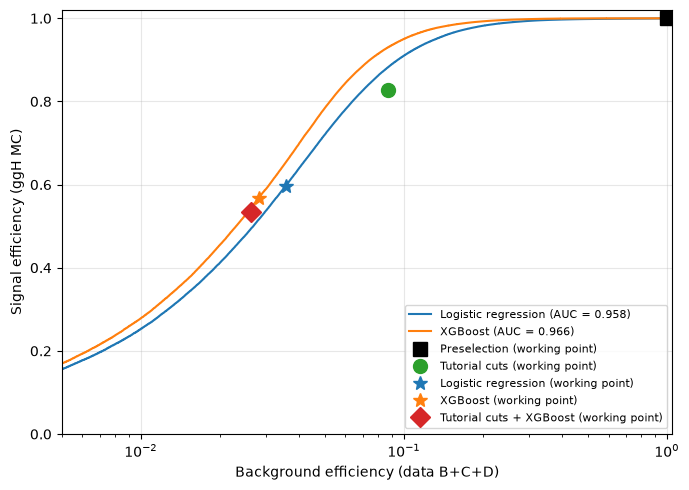

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, key in [("Logistic regression", "logreg"), ("XGBoost", "xgboost")]:
    fpr, tpr, _, auc = roc(sc[key]["sig_test"], s["w"], sc[key]["data_bcd"])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
markers = {"Preselection": "ks", "Tutorial cuts": "C2o", "Logistic regression": "C0*",
           "XGBoost": "C1*", "Tutorial cuts + XGBoost": "C3D"}
for name, r in R.items():
    ax.plot(1 - r["bkg. rej."], r["sig. eff."], markers[name], ms=10, label=f"{name} (working point)")
ax.set(xscale="log", xlim=(5e-3, 1.05), ylim=(0, 1.02),
       xlabel="Background efficiency (data B+C+D)", ylabel="Signal efficiency (ggH MC)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_roc.png", dpi=150); plt.show()

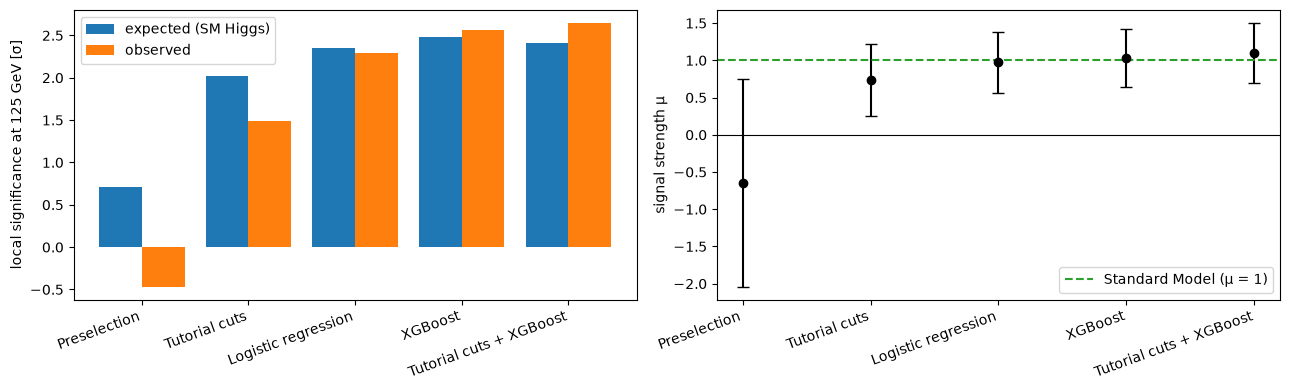

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(R)
x = np.arange(len(names))
ax[0].bar(x - 0.2, [R[n]["Z exp"] for n in names], 0.4, label="expected (SM Higgs)")
ax[0].bar(x + 0.2, [R[n]["Z obs"] for n in names], 0.4, label="observed")
ax[0].set_xticks(x, names, rotation=20, ha="right"); ax[0].set_ylabel("local significance at 125 GeV [σ]")
ax[0].legend()
ax[1].errorbar(x, [R[n]["μ"] for n in names], yerr=[R[n]["μ err"] for n in names], fmt="ko", capsize=4)
ax[1].axhline(1, color="C2", ls="--", label="Standard Model (μ = 1)")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(x, names, rotation=20, ha="right"); ax[1].set_ylabel("signal strength μ")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_significance_mu.png", dpi=150); plt.show()

## 4. m_γγ fits for every selection

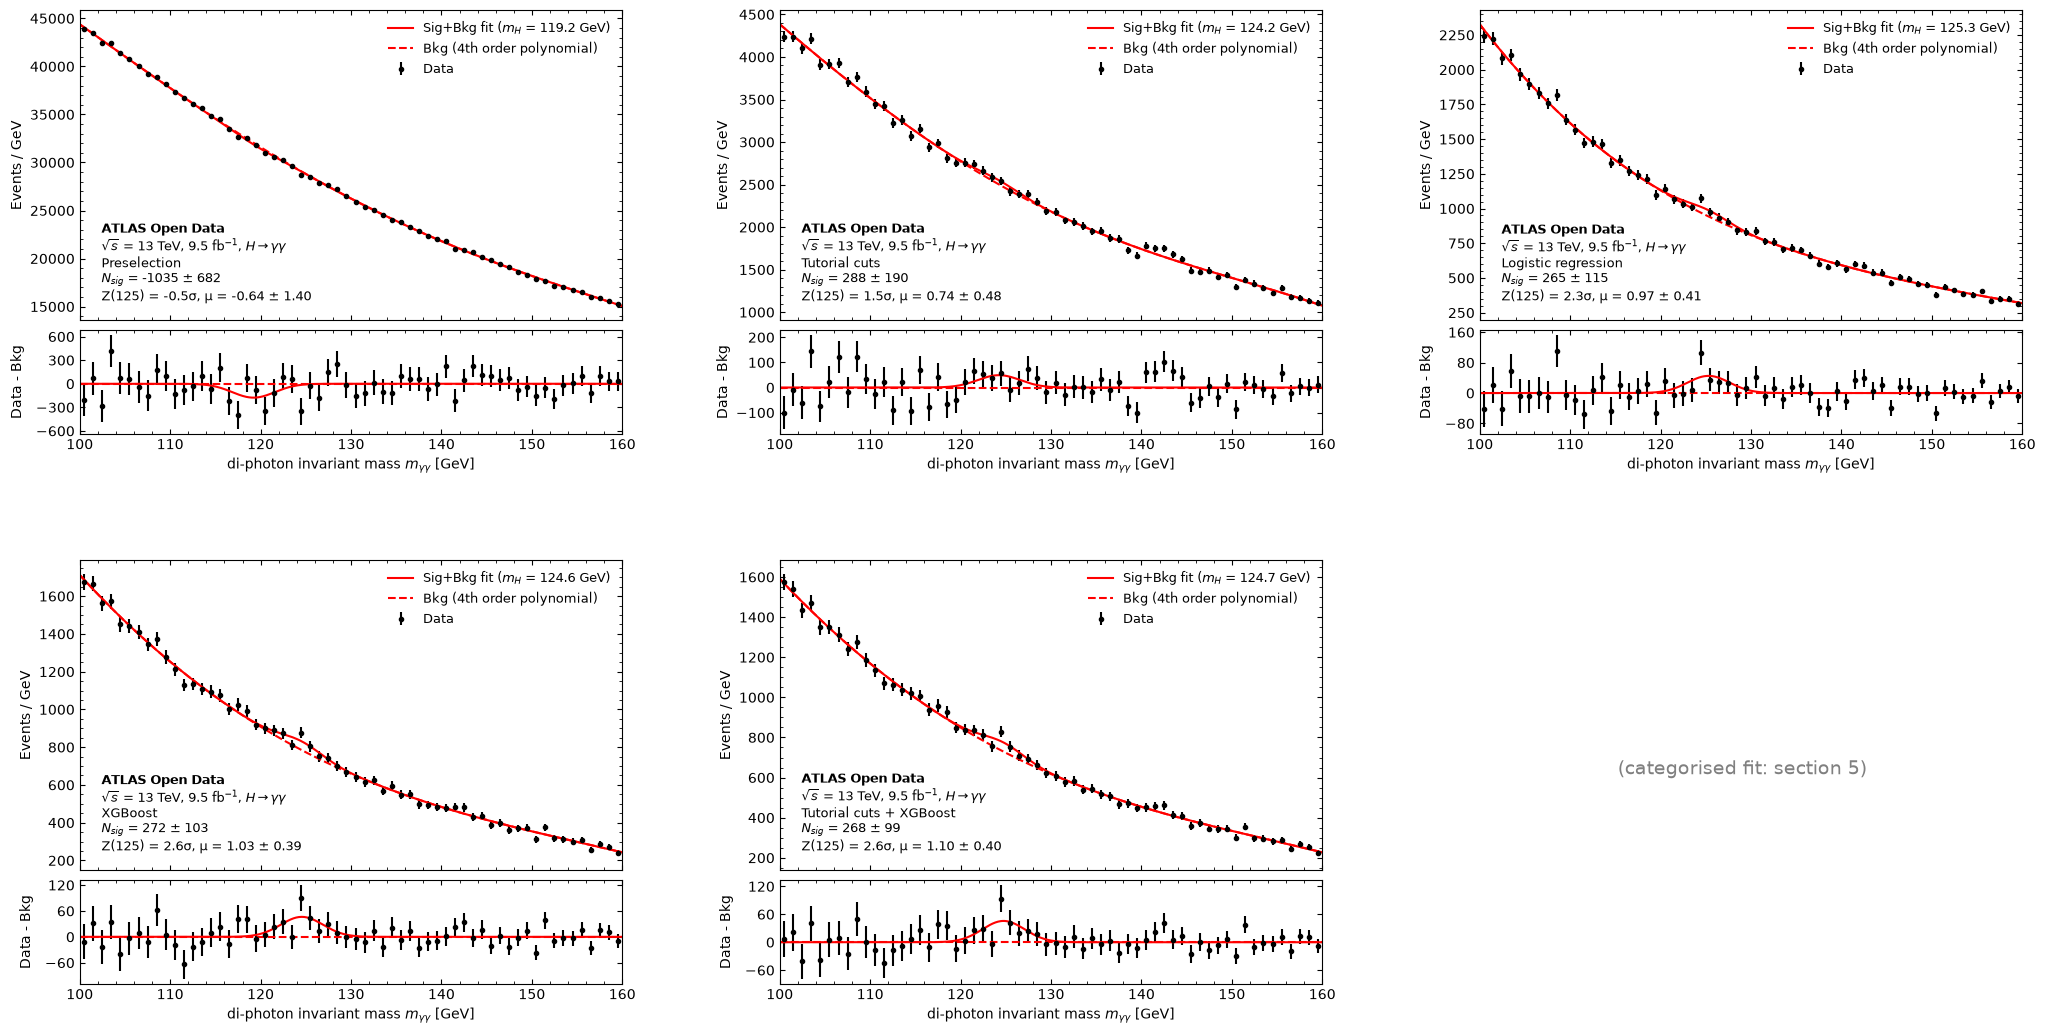

In [6]:
fig = plt.figure(figsize=(21, 11))
sub = fig.subfigures(2, 3)
for sf, (name, r) in zip(sub.flat, R.items()):
    plot_fit(r["_fit"], title=name, lumi=LUMI_TEST, fig=sf,
             label_extra=f"Z(125) = {r['Z obs']:.1f}σ, μ = {r['μ']:.2f} ± {r['μ err']:.2f}")
sub.flat[-1].text(0.5, 0.5, "(categorised fit: section 5)", ha="center", va="center", fontsize=14, color="grey")
plt.savefig(FIG_DIR / "comparison_myy_fits.png", dpi=110, bbox_inches="tight"); plt.show()

## 5. Using the whole BDT score: categories
A single cut throws away signal events that are only *somewhat* signal-like. Instead we split the events into bins of XGBoost score and fit all of them together with one common signal strength μ (each category keeps its own background polynomial). Purer categories then count for more.

To avoid tuning on the answer, the category boundaries are defined by signal-efficiency points on the **validation** MC, and the scheme is picked by the **expected** significance only. The observed values of all schemes are printed for transparency.

In [7]:
sv, wv = sc["xgboost"]["sig_val"], np.abs(D["sig_val"]["w"])
o = np.argsort(sv)[::-1]
cum = np.cumsum(wv[o]) / wv.sum()
def score_at_eff(eff):   # score value at which the validation signal efficiency reaches `eff`
    return sv[o][np.searchsorted(cum, eff)]

SCHEMES = {
    "1 cat (single cut)": ["cut"],
    "2 cats": [0.30, "cut"],
    "3 cats": [0.30, 0.57, 0.80],
    "4 cats": [0.30, 0.57, 0.80, 0.90],
    "5 cats": [0.25, 0.50, 0.70, 0.85, 0.95],
}

def categories(effs):
    # "cut" = the exact XGBoost cut of notebook 04
    edges = sorted([cut_xgb if e == "cut" else score_at_eff(e) for e in effs]) + [1.0 + 1e-9]
    bins = list(zip(edges[:-1], edges[1:]))
    my = [d["myy"][(sc["xgboost"]["data_bcd"] >= lo) & (sc["xgboost"]["data_bcd"] < hi)] for lo, hi in bins]
    S = [s["w"][(sc["xgboost"]["sig_test"] >= lo) & (sc["xgboost"]["sig_test"] < hi)].sum() for lo, hi in bins]
    return bins, my, S

cat_rows, cat_fits = {}, {}
for name, effs in SCHEMES.items():
    bins, my, S = categories(effs)
    cf = CategoryFit(my, S, SIGMA)
    cat_fits[name] = (bins, my, S, cf)
    cat_rows[name] = {"Z exp": cf.expected_Z(), "Z obs": cf.Z_local, "μ": cf.mu, "μ err": cf.mu_err,
                      "S total": sum(S)}
cat_table = pd.DataFrame(cat_rows).T
best_scheme = cat_table["Z exp"].idxmax()
print("scheme with the best EXPECTED significance:", best_scheme)
cat_table

scheme with the best EXPECTED significance: 5 cats


,Z exp,Z obs,μ,μ err,S total
1 cat (single cut),2.482,2.562,1.031,0.392,258.024
2 cats,2.575,2.811,1.091,0.375,258.024
3 cats,2.792,3.705,1.332,0.362,362.771
4 cats,2.836,3.896,1.380,0.356,408.900
5 cats,2.865,4.090,1.435,0.352,431.269


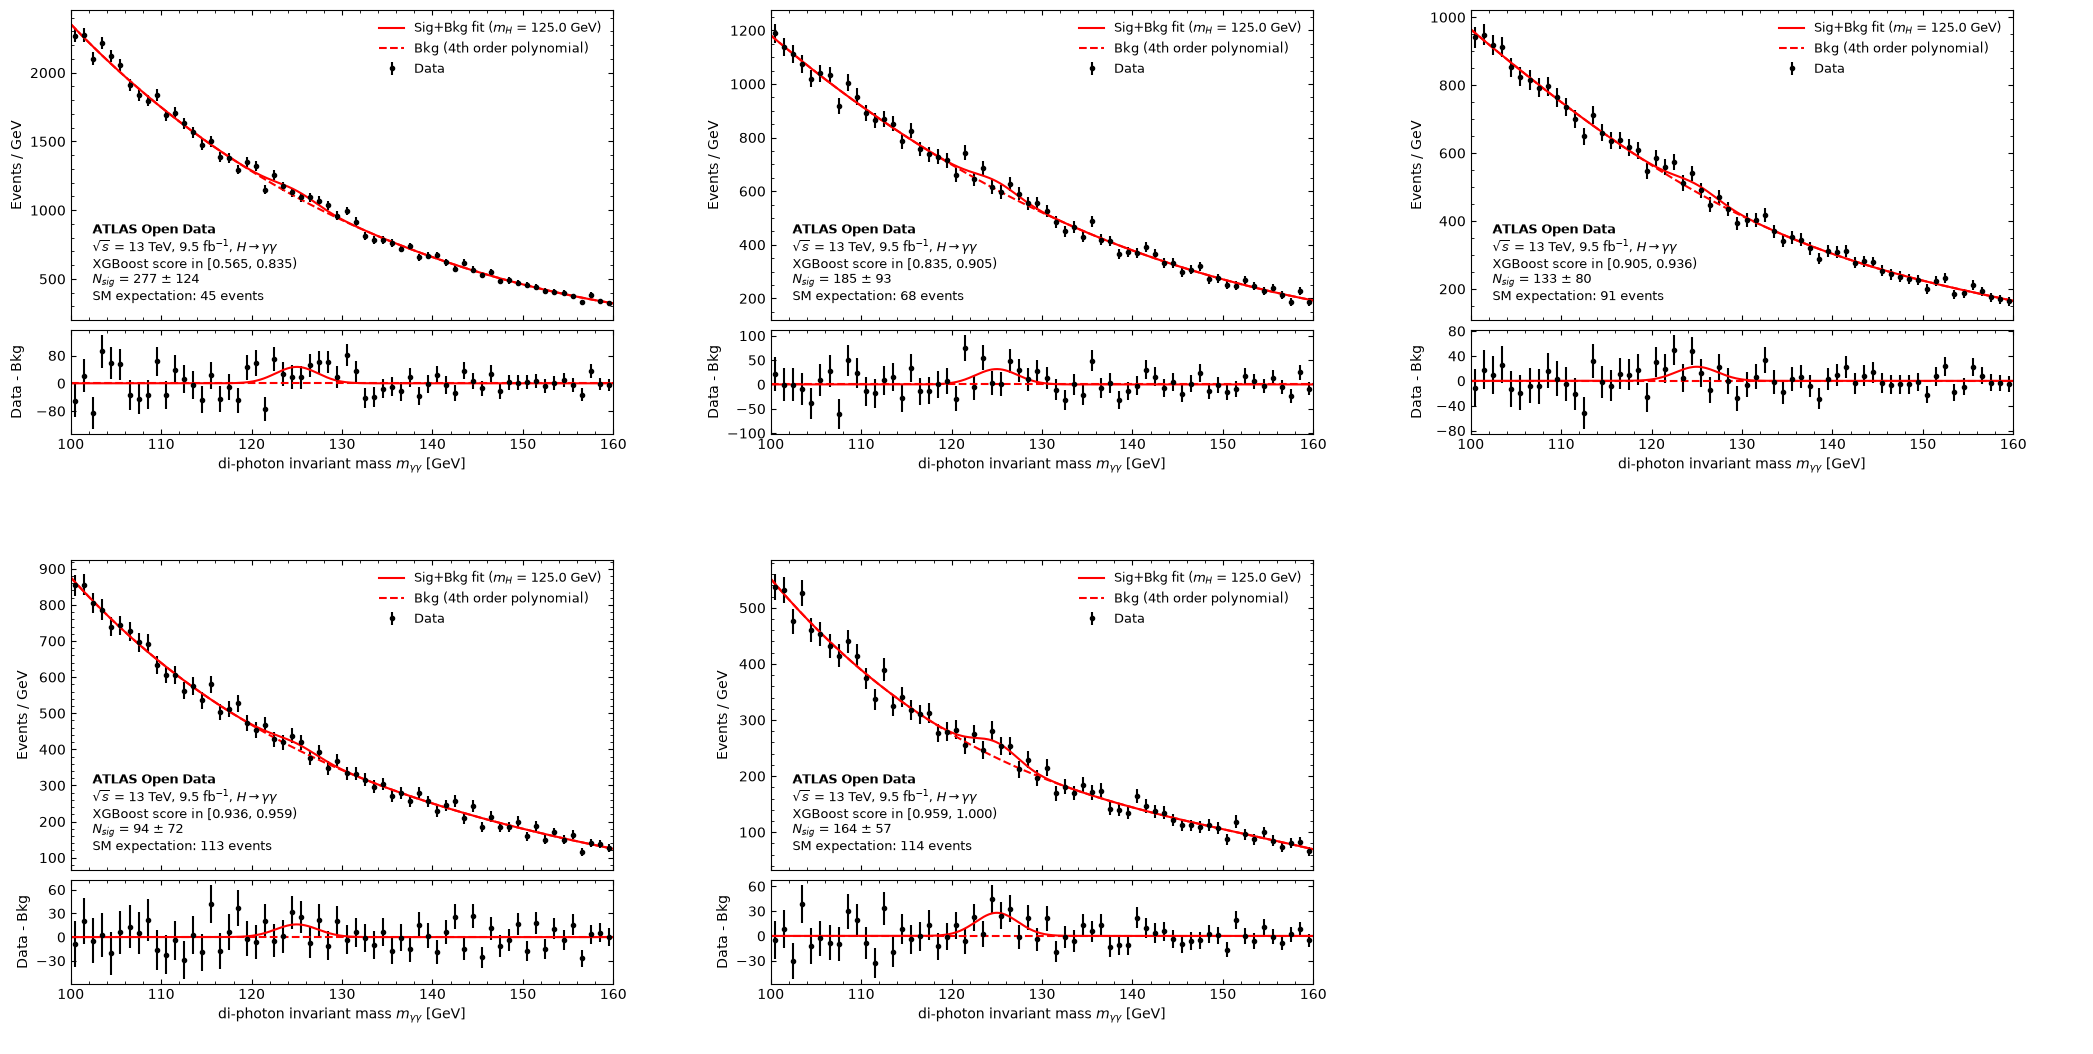

5 cats: μ = 1.43 ± 0.35,  Z_obs = 4.09σ,  Z_exp = 2.86σ


In [8]:
bins, my, S, cf = cat_fits[best_scheme]
ncol = 3
nrow = int(np.ceil(len(bins) / ncol))
fig = plt.figure(figsize=(21, 5.5 * nrow))
subs = fig.subfigures(nrow, ncol).flat
for i, (sf, (lo, hi), m, Sc) in enumerate(zip(subs, bins, my, S)):
    f = MyyFit(m, SIGMA, fix_mass=125.0)
    plot_fit(f, title=f"XGBoost score in [{lo:.3f}, {min(hi, 1):.3f})", lumi=LUMI_TEST, fig=sf,
             label_extra=f"SM expectation: {Sc:.0f} events")
for sf in list(subs):
    sf.text(0.5, 0.5, f"{best_scheme}\ncommon μ = {cf.mu:.2f} ± {cf.mu_err:.2f}\nZ_obs = {cf.Z_local:.2f}σ, Z_exp = {cf.expected_Z():.2f}σ",
            ha="center", va="center", fontsize=14)
plt.savefig(FIG_DIR / "categories_myy_fits.png", dpi=110, bbox_inches="tight"); plt.show()
print(f"{best_scheme}: μ = {cf.mu:.2f} ± {cf.mu_err:.2f},  Z_obs = {cf.Z_local:.2f}σ,  Z_exp = {cf.expected_Z():.2f}σ")

## 6. Is the excess really at 125 GeV? Local p-value scan
For every hypothesised mass between 110 and 150 GeV we refit with the signal mass fixed there and record the local p-value of the background-only hypothesis. A real Higgs boson produces a dip at its mass; a background fluctuation can appear anywhere. The dashed line is what an SM Higgs at 125 GeV would give on average (Asimov).

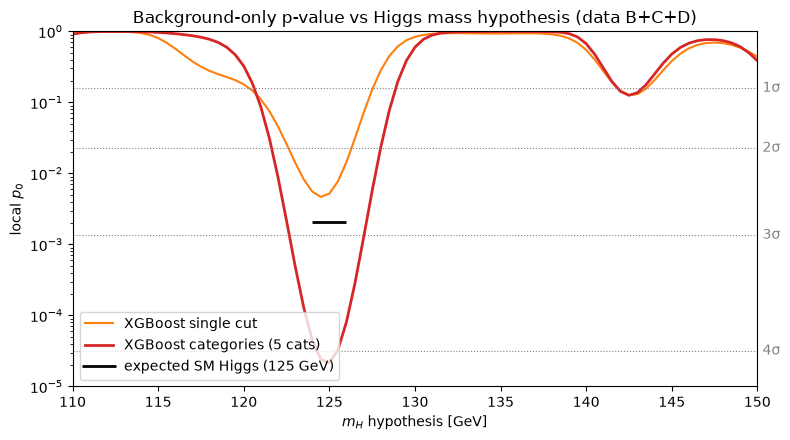

minimum p0 (categories) at m = 125.0 GeV:  p0 = 2.16e-05  (4.09σ local)


In [9]:
masses = np.arange(110, 150.01, 0.5)
best_mask = SEL["XGBoost"]

def p_scan(my, S, mass_grid):
    return np.array([CategoryFit(my, S, SIGMA, mass=m).p_local for m in mass_grid])

p_cut = p_scan([d["myy"][best_mask[1]]], [s["w"][best_mask[0]].sum()], masses)
p_cat = p_scan(my, S, masses)
from scipy.stats import norm
p_exp = norm.sf(cf.expected_Z())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(masses, p_cut, "C1-", label="XGBoost single cut")
ax.plot(masses, p_cat, "C3-", lw=2, label=f"XGBoost categories ({best_scheme})")
ax.plot(125, p_exp, "k_", ms=25, mew=2, label="expected SM Higgs (125 GeV)")
for z in range(1, 5):
    ax.axhline(norm.sf(z), color="grey", ls=":", lw=0.8)
    ax.text(150.3, norm.sf(z), f"{z}σ", va="center", color="grey")
ax.set(yscale="log", ylim=(1e-5, 1), xlim=(110, 150), xlabel=r"$m_H$ hypothesis [GeV]",
       ylabel="local $p_0$", title="Background-only p-value vs Higgs mass hypothesis (data B+C+D)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIG_DIR / "p0_scan.png", dpi=150); plt.show()
print(f"minimum p0 (categories) at m = {masses[np.argmin(p_cat)]:.1f} GeV:  p0 = {p_cat.min():.2e}  ({norm.isf(p_cat.min()):.2f}σ local)")

## 7. Stability across data-taking periods
If the excess is a real particle, its rate per fb⁻¹ is the same in each period and the fitted μ should agree within errors. Each period B, C, D is fitted on its own with the XGBoost categories (m_H = 125 GeV).

weighted mean μ = 1.44 ± 0.33;  χ²/ndf = 0.75/2 (consistency of the three periods)


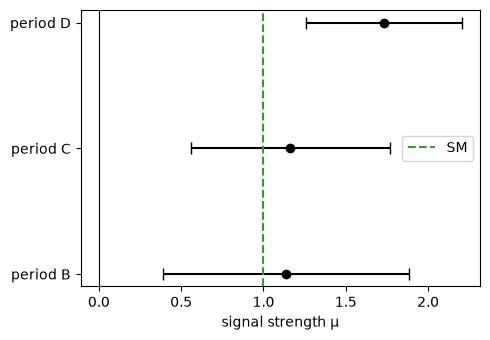

,lumi [fb^-1],S (SM),μ,μ err,Z obs,Z exp
B,1.900,86.254,1.139,0.748,1.442,1.265
C,2.900,131.650,1.162,0.604,1.832,1.589
D,4.700,213.365,1.731,0.474,3.478,2.021


In [10]:
from weights import LUMI
rows = {}
for p in ["B", "C", "D"]:
    dp, sp = D["data"][p], sc["xgboost"][f"data_{p}"]
    my_p = [dp["myy"][(sp >= lo) & (sp < hi)] for lo, hi in bins]
    S_p = [Sc * LUMI[p] / LUMI_TEST for Sc in S]   # MC is normalised to B+C+D; rescale
    f = CategoryFit(my_p, S_p, SIGMA)
    rows[p] = {"lumi [fb^-1]": LUMI[p], "S (SM)": sum(S_p), "μ": f.mu, "μ err": f.mu_err,
               "Z obs": f.Z_local, "Z exp": f.expected_Z()}
period_table = pd.DataFrame(rows).T

mus, errs = period_table["μ"].values, period_table["μ err"].values
w = 1 / errs**2
mu_comb = np.sum(w * mus) / w.sum()
chi2 = np.sum(((mus - mu_comb) / errs) ** 2)
print(f"weighted mean μ = {mu_comb:.2f} ± {w.sum()**-0.5:.2f};  χ²/ndf = {chi2:.2f}/2 (consistency of the three periods)")

plt.figure(figsize=(5, 3.5))
plt.errorbar(mus, range(3), xerr=errs, fmt="ko", capsize=4)
plt.axvline(1, color="C2", ls="--", label="SM")
plt.axvline(0, color="k", lw=0.8)
plt.yticks(range(3), [f"period {p}" for p in "BCD"])
plt.xlabel("signal strength μ"); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "mu_per_period.png", dpi=150); plt.show()
period_table

## 8. The headline plot

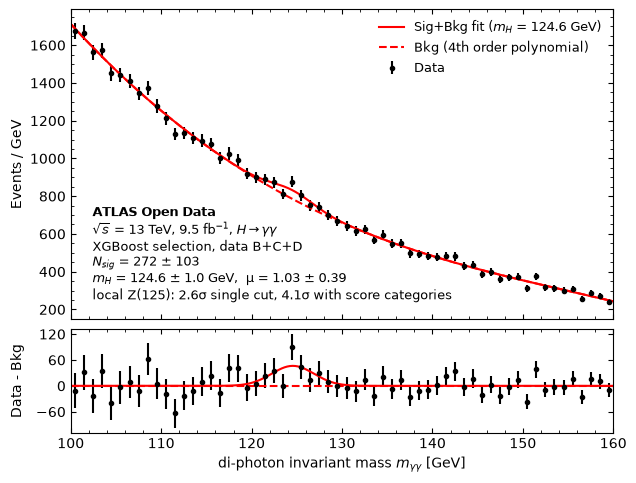

In [11]:
mask_s, mask_d = SEL["XGBoost"]
final = R["XGBoost"]["_fit"]
fig = plot_fit(final, title="XGBoost selection, data B+C+D", lumi=LUMI_TEST,
               label_extra=(f"$m_H$ = {final.mass:.1f} ± {final.mass_err:.1f} GeV,  μ = {R['XGBoost']['μ']:.2f} ± {R['XGBoost']['μ err']:.2f}\n"
                            f"local Z(125): {R['XGBoost']['Z obs']:.1f}σ single cut, {cf.Z_local:.1f}σ with score categories"))
plt.savefig(FIG_DIR / "final_higgs_peak.png", dpi=170, bbox_inches="tight"); plt.show()

In [12]:
# save everything the README quotes
out = {"selections": {k: {c: (float(v) if not isinstance(v, int) else v) for c, v in r.items() if not c.startswith("_")}
                      for k, r in R.items()},
       "categories": {k: {c: float(v) for c, v in r.items()} for k, r in cat_rows.items()},
       "best_scheme": best_scheme,
       "periods": {k: {c: float(v) for c, v in r.items()} for k, r in rows.items()},
       "p0_min_mass": float(masses[np.argmin(p_cat)]), "p0_min_Z": float(norm.isf(p_cat.min())),
       "mu_periods_combined": float(mu_comb), "chi2_periods": float(chi2)}
json.dump(out, open("../results/scores/global_comparison.json", "w"), indent=2)
table.to_csv("../results/scores/comparison_table.csv")
print(json.dumps(out["selections"]["XGBoost"], indent=1))

{
 "sig. eff.": 0.5683672699527034,
 "bkg. rej.": 0.9719362694564445,
 "N data": 46279,
 "S (SM, MC)": 258.024130126499,
 "B 120-130": 7766.285586804657,
 "S/\u221aB": 2.76681550501944,
 "Z exp": 2.4821696553089896,
 "N fit": 266.13674490183206,
 "N fit err": 101.25477736110263,
 "\u03bc": 1.031441302684969,
 "\u03bc err": 0.3924236749154485,
 "m_H": 124.56017928830757,
 "m_H err": 0.9822951073096888,
 "Z obs": 2.561593424076927
}


## Conclusions

**Classifier vs cuts (single selection, data B+C+D, 9.5 fb⁻¹)**
- Preselection alone sees nothing: S/√B ≈ 0.8 and the fit wanders off to 119 GeV with a negative yield.
- The tutorial cuts (isolation + tight ID) are the big step: they reject 91% of the background and keep 83% of the signal → expected 2.0σ, observed 1.5σ.
- Logistic regression (expected 2.35σ, observed 2.3σ) and XGBoost (expected 2.5σ, observed 2.6σ) both beat the tutorial cuts. XGBoost reaches 97.2% background rejection at 57% signal efficiency. At 80% signal efficiency it lets through ~18% less background than the logistic regression (5.2% vs 6.4% of the data).
- Ablation: adding the tutorial cuts *before* the XGBoost cut does not raise the expected significance (2.41σ vs 2.48σ). The BDT already uses the isolation and ID variables, so the hard cuts only remove signal it would have kept. The tutorial cuts are useful as a hand-made selection but redundant once a classifier sees the same variables.
- Every selection that sees a signal measures μ consistent with the SM (μ = 1) and m_H between 124.2 and 125.3 GeV.

**Score categories.** Fitting XGBoost score categories with one common μ is the most sensitive method (expected 2.9σ vs 2.5σ for the single cut). The 5-category scheme was picked on expected significance alone. It observes **4.1σ local at 125 GeV, μ = 1.43 ± 0.35**. That is above expectation, mainly because the loosest category fluctuates up (277 ± 124 fitted vs 45 expected). The single-cut result (2.6σ, μ = 1.03 ± 0.39) is the more conservative headline.

**Is it the Higgs boson?**
1. A narrow excess appears in the diphoton spectrum. Its width matches the detector resolution from the Higgs MC.
2. Its fitted mass, 124.6 ± 1.0 GeV, agrees with m_H = 125 GeV, and the background-only p-value scan reaches its minimum at exactly 125.0 GeV.
3. Its size matches the Standard Model prediction from simulation (μ ≈ 1).
4. It appears with every independent selection, and in each data-taking period B, C, D with consistent rates (χ²/ndf = 0.75/2).
5. It is not made by the selection: the m_γγ variable is never shown to the classifiers, the cut efficiency changes smoothly with mass, and notebook 04 shows what a real sculpting artefact looks like (a fake μ ≈ 32).

Caveats: significances are local (no look-elsewhere correction) and statistical only (no systematics). The 9.5 fb⁻¹ used here (data A is reserved for training) are not enough for a 5σ discovery on their own.